<a href="https://colab.research.google.com/github/sitizaniahuny/step-1-BPPN-skripsi-/blob/main/step%201%20Ver%203%20(model%204%20stations).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor

In [2]:
FILE_NAME = "/content/passengers.xlsx"

MAX_MISSING_PCT = 10
REMOVE_HIGH_MISSING = True

In [3]:
if FILE_NAME.lower().endswith(".csv"):
    df = pd.read_csv(FILE_NAME)

elif FILE_NAME.lower().endswith(".xlsx"):
    df = pd.read_excel(FILE_NAME)

else:
    raise ValueError("Please use a CSV or XLSX file.")
print("ORIGINAL DATA")
print(df.head())

print("\nData size:",df.shape)
print("\nColumn names:")
print(df.columns.tolist())

ORIGINAL DATA
        Station      Month  Passengers
0  Adi Soemarmo 2018-01-01         NaN
1  Adi Soemarmo 2018-02-01         NaN
2  Adi Soemarmo 2018-03-01         NaN
3  Adi Soemarmo 2018-04-01         NaN
4  Adi Soemarmo 2018-05-01         NaN

Data size: (2813, 3)

Column names:
['Station', 'Month', 'Passengers']


In [4]:
df = df.rename(columns={"Nama_Stasiun": "Station","Bulan": "Month","Jumlah_Penumpang": "Passengers"})
required_columns = ["Station","Month","Passengers"]
for col in required_columns:

    if col not in df.columns:

        raise ValueError(f"Column '{col}' was not found.")

#**Cleaning**

convert month to date

In [5]:
df["Month"] = pd.to_datetime(df["Month"],errors="coerce")

make all dates as the first day of each month

In [6]:
df["Month"] = (df["Month"].dt.to_period("M").dt.to_timestamp())

convert passangers numbers as numeric

In [7]:
df["Passengers"] = pd.to_numeric(df["Passengers"],errors="coerce")

remove missing stations atau missing months

In [8]:
df = df.dropna(subset=["Station","Month"]).copy()

clean station names

In [9]:
df["Station"] = (df["Station"].astype(str).str.strip())

##kode tambahan (karna mau modelin 4 stations)

In [10]:
SELECTED_STATIONS = [ "Yogyakarta", "Lempuyangan", "Purwosari", "Solo Balapan" ]
df = df[df["Station"].isin(SELECTED_STATIONS)].copy()
print("Stations in the analysis:")
print(sorted(df["Station"].unique()))
print("Number of stations:", df["Station"].nunique())

Stations in the analysis:
['Lempuyangan', 'Purwosari', 'Solo Balapan', 'Yogyakarta']
Number of stations: 4


##duplicate check

If more than one record exists for the same
station and month, passenger values are summed.

This is appropriate if several records represent
components of the monthly total.

In [11]:
duplicate_count = df.duplicated(
    subset=["Station","Month"]).sum()
print("DUPLICATE CHECK")
print("Number of duplicate Station-Month records:",duplicate_count)

DUPLICATE CHECK
Number of duplicate Station-Month records: 0


In [12]:
df = (df.groupby(["Station","Month"],as_index=False)
    .agg(Passengers=("Passengers",lambda x: x.sum(min_count=1))))

data sorting

In [14]:
df = df.sort_values(
    ["Station","Month"]
).reset_index(
    drop=True)

monthly series

In [15]:
complete_data = []
for station in df["Station"].unique():
    temp = df[
        df["Station"] == station
    ].copy()
    temp = temp.sort_values("Month")

    full_months = pd.date_range(
        start=temp["Month"].min(),
        end=temp["Month"].max(),
        freq="MS"
    )

    temp = (temp.set_index("Month").reindex(full_months))

    temp.index.name = "Month"


    #Restore station name
    temp["Station"] = station
    complete_data.append(temp)

df_complete = pd.concat(
    complete_data
).reset_index()

df_complete = df_complete.sort_values(
    ["Station","Month"]
).reset_index(
    drop=True)

missing value identification

In [16]:
df_complete["Was_Missing"] = (
    df_complete["Passengers"]
    .isna()
    .astype(int))

print("MISSING DATA")
print("Total missing observations:",df_complete["Was_Missing"].sum())


MISSING DATA
Total missing observations: 0


missing value per stations

In [17]:
missing_summary = (
    df_complete
    .groupby("Station")
    .agg(Total_Months=("Month","size"),Missing_Months=("Was_Missing","sum"))
    .reset_index())

missing_summary["Missing_Percentage"] = (missing_summary["Missing_Months"]
    /
    missing_summary["Total_Months"]
    * 100)

missing_summary = (missing_summary.sort_values("Missing_Percentage",ascending=False)
    .reset_index(drop=True))
print("\nMissing data by station:")
print(missing_summary)


Missing data by station:
        Station  Total_Months  Missing_Months  Missing_Percentage
0   Lempuyangan            97               0                 0.0
1     Purwosari            97               0                 0.0
2  Solo Balapan            97               0                 0.0
3    Yogyakarta            97               0                 0.0


identify missing per stations

In [18]:
high_missing_stations = (
    missing_summary[
        missing_summary[
            "Missing_Percentage"
        ] > MAX_MISSING_PCT
    ]["Station"]
    .tolist())
print(f"\nStations with more than "f"{MAX_MISSING_PCT}% missing:")
print(high_missing_stations)
if REMOVE_HIGH_MISSING:
    df_complete = df_complete[
        ~df_complete[
            "Station"].isin(high_missing_stations)
    ].copy()
    print("\nStations with high missing data "
    "have been removed.")



Stations with more than 10% missing:
[]

Stations with high missing data have been removed.


udah gaada missing > 10%

#Impute Missing Value

biar ga pake future leakage;
1st choice nya t-12 (pake data bulan yg sama tp di tahun sebelumnya)
2nd choice nya pake t-1

In [19]:
def historical_imputation(group):
    group = group.sort_values("Month").copy()
    values = (
        group["Passengers"]
        .astype(float)
        .to_numpy())


    for i in range(
        len(values)):
        if np.isnan(
            values[i]):

            # First choice: t-12
            # same month previous year
            if (
                i >= 12
                and
                not np.isnan(
                    values[i - 12]
                )
            ):

                values[i] = (
                    values[i - 12]
                )


            # Second choice: t-1
            # previous month
            elif (
                i >= 1
                and
                not np.isnan(
                    values[i - 1]
                )
            ):
                values[i] = (
                    values[i - 1])


    group["Passengers_Filled"] = values
    return group

df_complete = (df_complete.groupby("Station",group_keys=False)
    .apply(historical_imputation)
    .reset_index(
        drop=True))

/tmp/ipykernel_3555/4153433201.py:46: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(historical_imputation)


In [20]:
remaining_missing = (
    df_complete["Passengers_Filled"]
    .isna()
    .sum())

print("AFTER IMPUTATION")
print("Remaining missing values:",
    remaining_missing)

df_complete = (df_complete
    .dropna(subset=["Passengers_Filled"])
    .copy())

AFTER IMPUTATION
Remaining missing values: 0


##Create Month Variable

In [21]:
df_complete["month_num"] = (
    df_complete["Month"]
    .dt.month)

create time index (month 1 = 0, month 2 = 1, dst)

In [22]:
df_complete["time_index"] = (df_complete
    .groupby("Station")
    .cumcount())

print("\nExample of Time Index:")
print(df_complete[
        ["Station","Month","Passengers_Filled","time_index"]]
    .head(200))


Example of Time Index:
          Station      Month  Passengers_Filled  time_index
0     Lempuyangan 2018-01-01           132477.0           0
1     Lempuyangan 2018-02-01           123899.0           1
2     Lempuyangan 2018-03-01           129302.0           2
3     Lempuyangan 2018-04-01           140127.0           3
4     Lempuyangan 2018-05-01           119589.0           4
..            ...        ...                ...         ...
195  Solo Balapan 2018-02-01           188147.0           1
196  Solo Balapan 2018-03-01           211577.0           2
197  Solo Balapan 2018-04-01           214324.0           3
198  Solo Balapan 2018-05-01           201499.0           4
199  Solo Balapan 2018-06-01           249422.0           5

[200 rows x 4 columns]


#**Lag**

In [23]:
lags = [1,2,3,6,12]
for lag in lags:

    df_complete[
        f"lag_{lag}"
    ] = (df_complete
        .groupby("Station"
        )["Passengers_Filled"]
        .shift(lag))

hapus rows tanpa pengaruhi suff lag history

In [24]:
df_model = (
    df_complete
    .dropna(subset=[
            "lag_1",
            "lag_2",
            "lag_3",
            "lag_6",
            "lag_12"])
    .copy())

print("DATA READY FOR MODELLING")

print(df_model[
        ["Station","Month","Passengers_Filled",
            "month_num","time_index","lag_1",
            "lag_2","lag_3","lag_6","lag_12"]
    ].head())

print("\nNumber of observations:",len(df_model))

DATA READY FOR MODELLING
        Station      Month  Passengers_Filled  month_num  time_index  \
12  Lempuyangan 2019-01-01           150970.0          1          12   
13  Lempuyangan 2019-02-01           139536.0          2          13   
14  Lempuyangan 2019-03-01           148519.0          3          14   
15  Lempuyangan 2019-04-01           166806.0          4          15   
16  Lempuyangan 2019-05-01           122302.0          5          16   

       lag_1     lag_2     lag_3     lag_6    lag_12  
12  175455.0  146236.0  132516.0  157547.0  132477.0  
13  150970.0  175455.0  146236.0  155730.0  123899.0  
14  139536.0  150970.0  175455.0  135853.0  129302.0  
15  148519.0  139536.0  150970.0  132516.0  140127.0  
16  166806.0  148519.0  139536.0  146236.0  119589.0  

Number of observations: 340


#**Def Predictors & Target**

In [25]:
features = ["Station", "month_num", "time_index", "lag_1", "lag_2", "lag_3", "lag_6", "lag_12"]
target = ("Passengers_Filled")

In [26]:
features = [
    "Station",
    "month_num",
    "time_index",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_6",
    "lag_12"
]
target = (
    "Passengers_Filled")

#**Train, Validation, & Test Split**
Training: sebelum 1 Jan 2024
Validation: Jan-Dec 2024
Test: Jan 2025 dst

In [27]:
train = ( df_model[ df_model["Month"] < "2024-01-01"]
    .copy())

validation = (df_model[
        (df_model["Month"] >= "2024-01-01")
        &
        (df_model["Month"] < "2025-01-01")]
    .copy())

test = (df_model[df_model[ "Month"] >= "2025-01-01"]
    .copy())

original target untuk training

In [29]:
train_original = (train[train["Was_Missing"] == 0]
                  .copy())


validation_original = (validation[validation["Was_Missing"] == 0]
                       .copy())

buat X & Y Data

In [30]:
X_train = ( train_original[features])
y_train = ( train_original[target])
X_val = (validation_original[features])
y_val = (validation_original[target])

X_test_all = (test[features])

print("DATA SPLIT")
print("Training:",len(train_original))
print("Validation:",len(validation_original))
print("Testing:",len(test))

DATA SPLIT
Training: 240
Validation: 48
Testing: 52


In [31]:
print('Number of unique stations in Training set:', X_train['Station'].nunique())
print('Number of unique stations in Validation set:', X_val['Station'].nunique())
print('Number of unique stations in Test set:', X_test_all['Station'].nunique())

Number of unique stations in Training set: 4
Number of unique stations in Validation set: 4
Number of unique stations in Test set: 4


In [32]:
numeric_features = [
    "month_num",
    "time_index",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_6",
    "lag_12"]
categorical_features = [
    "Station"]

#**Preprocessing**

In [33]:
preprocessor = ColumnTransformer(transformers=[("numeric",StandardScaler(),numeric_features),
        ("station",OneHotEncoder( handle_unknown="ignore"),categorical_features)])

#**Backpropagation (MLP Model)**

In [35]:
mlp = MLPRegressor(
    hidden_layer_sizes=(16,8),
    activation="relu",
    solver="adam",
    learning_rate_init=0.01,
    max_iter=2000,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=50,
    random_state=123
)

pipeline

In [36]:
pipeline = Pipeline(
    steps=[("preprocessing",preprocessor),("mlp",mlp)])

Scale target variable

In [37]:
model = TransformedTargetRegressor(
    regressor=pipeline,
    transformer=StandardScaler())

#**Train BPPN**

In [38]:
print("TRAINING BACKPROPAGATION MODEL")
model.fit(
    X_train,
    y_train)
print("Training completed.")

TRAINING BACKPROPAGATION MODEL
Training completed.


##**Validation Perfomance**

In [39]:
if len(validation_original) > 0:
    y_val_pred = (model.predict(X_val))
    val_mae = mean_absolute_error( y_val,y_val_pred)
    val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
    val_mask = (y_val != 0)
    val_mape = (np.mean(np.abs((y_val[ val_mask]-y_val_pred[val_mask])/y_val[val_mask]))* 100)


    print("VALIDATION PERFORMANCE - 2024")
    print(f"MAE  : {val_mae:,.2f}")
    print(f"RMSE : {val_rmse:,.2f}")
    print(f"MAPE : {val_mape:.2f}%")

VALIDATION PERFORMANCE - 2024
MAE  : 19,137.41
RMSE : 22,314.72
MAPE : 29.27%


In [40]:
test["Prediction_Backprop"] = (model.predict(X_test_all))
#Passenger predictions theoretically should notbe negative. If the neural network produces a negative value, set it to zero.
test["Prediction_Backprop"] = (test["Prediction_Backprop"]
    .clip(lower=0 ))

##**Test Eval**

In [41]:
test_evaluation = (
    test[test["Was_Missing"] == 0]
    .copy())
y_test = (test_evaluation["Passengers"])
y_pred = (test_evaluation["Prediction_Backprop"])

###test MAE RMSE MAPE

In [42]:
test_mae = mean_absolute_error(y_test,y_pred)
test_rmse = np.sqrt(mean_squared_error(y_test,y_pred))
test_mask = (y_test != 0)
test_mape = (np.mean(np.abs((y_test[test_mask]-y_pred[test_mask])/y_test[test_mask]))* 100)

In [43]:
print("BACKPROPAGATION TEST PERFORMANCE")
print("2025-2026")
print(f"MAE  : {test_mae:,.2f}")
print(f"RMSE : {test_rmse:,.2f}")
print(f"MAPE : {test_mape:.2f}%")

BACKPROPAGATION TEST PERFORMANCE
2025-2026
MAE  : 29,043.41
RMSE : 33,089.07
MAPE : 54.18%


In [44]:
print("Jumlah stasiun pada data test:",
      test_evaluation["Station"].nunique())

print("Jumlah observasi test per stasiun:")
print(test_evaluation.groupby("Station").size())

Jumlah stasiun pada data test: 4
Jumlah observasi test per stasiun:
Station
Lempuyangan     13
Purwosari       13
Solo Balapan    13
Yogyakarta      13
dtype: int64


In [45]:
print("Total penumpang per stasiun pada data test:")
print(test_evaluation.groupby("Station")["Passengers"].sum())

Total penumpang per stasiun pada data test:
Station
Lempuyangan     1623681.0
Purwosari        296209.0
Solo Balapan    1707366.0
Yogyakarta      3324922.0
Name: Passengers, dtype: float64


In [46]:
print("Rentang penumpang per stasiun pada data test:")
print(test_evaluation.groupby("Station")["Passengers"].agg(['min', 'max']))

Rentang penumpang per stasiun pada data test:
                   min       max
Station                         
Lempuyangan    77303.0  148127.0
Purwosari      18806.0   28561.0
Solo Balapan  104327.0  161216.0
Yogyakarta    155200.0  322747.0


#**Seasonal Naive Bayes**
Seasonal Naive prediction: Y_hat(t) = Y(t-12)
Example: prediction for March 2025 = passengers in March 2024

In [47]:
test_evaluation["Prediction_Naive"] = test_evaluation["lag_12"]

MAE RMSE MAPE

In [48]:
naive_mae = mean_absolute_error(
    test_evaluation["Passengers"],
    test_evaluation["Prediction_Naive"])

naive_rmse = np.sqrt(
    mean_squared_error(
        test_evaluation["Passengers"],
        test_evaluation["Prediction_Naive"]))

naive_mask = test_evaluation["Passengers"] != 0

naive_mape = (
    np.mean(
        np.abs(
            (
                test_evaluation.loc[naive_mask, "Passengers"]
                - test_evaluation.loc[naive_mask, "Prediction_Naive"]
            )
            / test_evaluation.loc[naive_mask, "Passengers"]
        )
    )
    * 100
)

comparison

In [49]:
comparison = pd.DataFrame({
    "Model": ["Backpropagation", "Seasonal Naive"],
    "MAE": [test_mae, naive_mae],
    "RMSE": [test_rmse, naive_rmse],
    "MAPE": [test_mape, naive_mape]
})

print("MODEL COMPARISON")
print(comparison)

MODEL COMPARISON
             Model           MAE          RMSE       MAPE
0  Backpropagation  29043.408012  33089.072738  54.176975
1   Seasonal Naive  13723.903846  17390.134623  12.752657


test error

In [50]:
test["Error"] = test["Passengers_Filled"] - test["Prediction_Backprop"]
test["Absolute_Error"] = np.abs(test["Error"])

performance by stations

In [52]:
station_results = []

for station in test_evaluation["Station"].unique():
    temp = test_evaluation[test_evaluation["Station"] == station].copy()

    if len(temp) == 0:
        continue

    #MAE
    station_mae = mean_absolute_error(
        temp["Passengers"],
        temp["Prediction_Backprop"]
    )

    #RMSE
    station_rmse = np.sqrt(
        mean_squared_error(
            temp["Passengers"],
            temp["Prediction_Backprop"]
        )
    )

    #MAPE
    mask = temp["Passengers"] != 0

    if mask.sum() > 0:
        station_mape = (
            np.mean(
                np.abs(
                    (
                        temp.loc[mask, "Passengers"]
                        - temp.loc[mask, "Prediction_Backprop"]
                    )
                    / temp.loc[mask, "Passengers"]
                )
            )
            * 100
        )
    else:
        station_mape = np.nan

    station_results.append({
        "Station": station,
        "Number_of_Test_Months": len(temp),
        "MAE": station_mae,
        "RMSE": station_rmse,
        "MAPE": station_mape
    })

station_evaluation = (
    pd.DataFrame(station_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("PERFORMANCE BY STATION")
print(station_evaluation)

PERFORMANCE BY STATION
        Station  Number_of_Test_Months           MAE          RMSE        MAPE
0   Lempuyangan                     13  20574.856451  24816.611146   18.770241
1  Solo Balapan                     13  23376.092471  26913.274243   19.360975
2     Purwosari                     13  36285.701066  36744.890023  163.482005
3    Yogyakarta                     13  35936.982062  41099.531343   15.094679


In [54]:
OUTPUT_FILE = "hasil_modeling 4 stations.xlsx"

with pd.ExcelWriter(OUTPUT_FILE) as writer:
    missing_summary.to_excel(writer, sheet_name="Missing Summary", index=False)
    df_complete.to_excel(writer, sheet_name="Clean Data", index=False)
    test.to_excel(writer, sheet_name="Predictions", index=False)
    comparison.to_excel(writer, sheet_name="Model Comparison", index=False)
    station_evaluation.to_excel(writer, sheet_name="Station Evaluation", index=False)

print("OUTPUT")
print("Results saved as:", OUTPUT_FILE)

OUTPUT
Results saved as: hasil_modeling 4 stations.xlsx


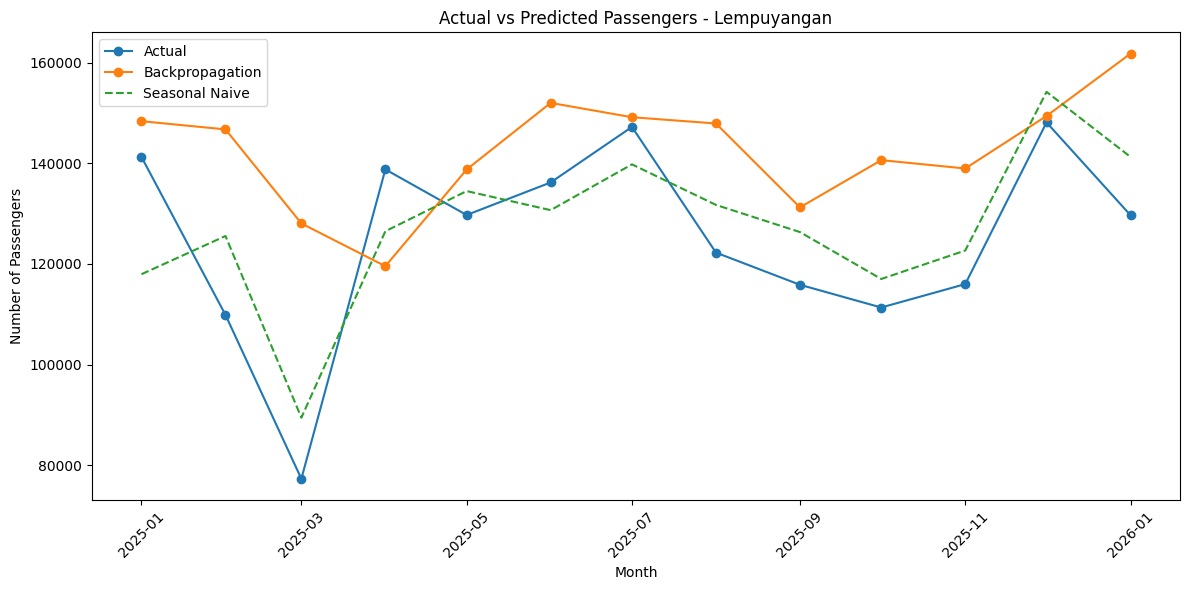

In [55]:
station_name = test_evaluation["Station"].iloc[0]
plot_data = test_evaluation[test_evaluation["Station"] == station_name].copy()

plt.figure(figsize=(12, 6))

# Actual
plt.plot(plot_data["Month"], plot_data["Passengers"], marker="o", label="Actual")

# Backpropagation
plt.plot(plot_data["Month"], plot_data["Prediction_Backprop"], marker="o", label="Backpropagation")

# Seasonal Naive
plt.plot(plot_data["Month"], plot_data["lag_12"], linestyle="--", label="Seasonal Naive")

plt.xlabel("Month")
plt.ylabel("Number of Passengers")
plt.title(f"Actual vs Predicted Passengers - {station_name}")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

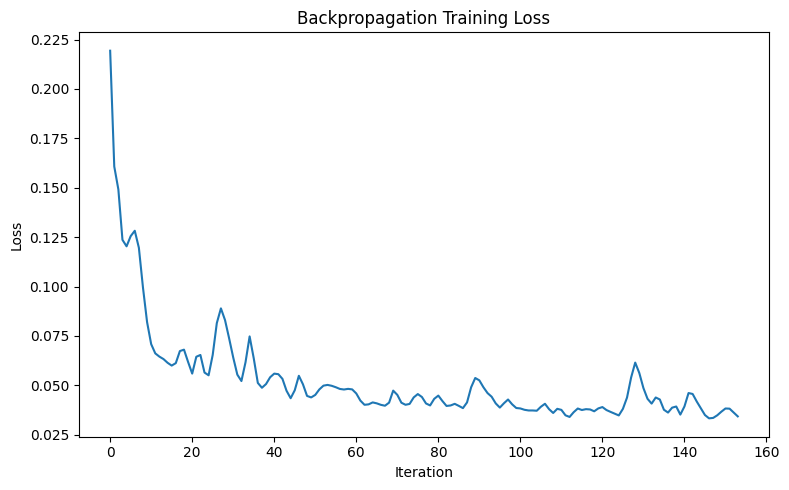

In [56]:
trained_pipeline = model.regressor_
trained_mlp = trained_pipeline.named_steps["mlp"]

plt.figure(figsize=(8, 5))
plt.plot(trained_mlp.loss_curve_)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Backpropagation Training Loss")
plt.tight_layout()
plt.show()

In [57]:
print("TRAINING INFORMATION")
print("Number of iterations:", trained_mlp.n_iter_)
print("Final training loss:", trained_mlp.loss_)
print("\nProgram finished successfully.")

TRAINING INFORMATION
Number of iterations: 154
Final training loss: 0.03426997390067721

Program finished successfully.
